In [1]:
import os
os.environ['CUBLAS_WORKSPACE_CONFIG'] = ':4096:8'
import random
import numpy as np
import pandas as pd
import torch

from eeg_seizure_cls.config import RAW_DATA_DIR, MODELS_DIR
from eeg_seizure_cls.dataset import generate_splits, generate_class_weights, transform, TimeSeriesDataset, ScaledMLPDataset, SpectrogramImageDataset, MultiModalDataset
from eeg_seizure_cls.features import extract_stat_features, build_clean_df, build_yj_df, summarize_features
from eeg_seizure_cls.plots import viz_sampled_eeg, viz_feature_boxplots, viz_feature_hists, viz_spectrograms, generate_val_report
from eeg_seizure_cls.modeling.train import ts_objective, mlp_objective, mult_objective, run_hpo, save_best_params, load_best_params, ts_train_val_loop, mlp_train_val_loop, resnet_train_val_loop, mult_train_val_loop, save_out_dict, load_out_dict, load_trained_model
from eeg_seizure_cls.modeling.predict import eval_model, test_eval_model

SEED = 0
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = True
torch.use_deterministic_algorithms(True, warn_only=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(DEVICE)

cuda


In [2]:
DATA_PATH = RAW_DATA_DIR / 'Epileptic Seizure Recognition'
raw_df = pd.read_csv(DATA_PATH / 'Epileptic Seizure Recognition.csv', sep=',')

In [3]:
display(raw_df.head(10))
na_vals = raw_df.loc[:, ~raw_df.columns.isin(['Unnamed', 'y'])].isna().any().any()
split_col_a = raw_df['Unnamed'].copy().str.split('.', n=1, expand=True)
#labels = raw_df['y'].copy().unique()

print(f'NAs in Dataset: {na_vals}')
print(f'No. Unique Xnn Identifiers: {split_col_a.iloc[:, 0].nunique()}') # Xnn -> unique per second sequence order identifier of 23 second recording (23 uniques)
print(f'No. Unique Vn.nnn Identifiers: {split_col_a.iloc[:, 1].nunique()}') # Vn.nnn -> unique patient identifier (500 unique)
print(f"List of Unique Class Labels: {[int(i) for i in sorted(raw_df['y'].unique())]}") # only 1 is positive indication of seizure to be recognized. condense 2 thru 5 to 0
print(f'No. Time-series Features: {len(raw_df.columns) - 2}')

# dataset contains a SHUFFLED compilation of 23-second EEG recordings across 500 unique patients, where each 23-second recording from a unique patient is split into 23x 1-second examples
# each 1-second example has 178 time-series features (X1, ..., X178 in sequential order) each representing an EEG value read per 1/178 second interval.

,Unnamed,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,y
0,X21.V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,4
1,X15.V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,X8.V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,5
3,X16.V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,5
4,X20.V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,5
5,X14.V1.56,55,28,18,16,16,19,25,40,52,...,-12,-31,-42,-54,-60,-64,-60,-56,-55,5
6,X3.V1.191,-55,-9,52,111,135,129,103,72,37,...,-125,-99,-79,-62,-41,-26,11,67,128,4
7,X11.V1.273,1,-2,-8,-11,-12,-17,-15,-16,-18,...,-79,-91,-97,-88,-76,-72,-66,-57,-39,2
8,X19.V1.874,-278,-246,-215,-191,-177,-167,-157,-139,-118,...,-400,-379,-336,-281,-226,-174,-125,-79,-40,1
9,X3.V1.491,8,15,13,3,-6,-8,-5,4,25,...,49,31,11,-5,-17,-19,-15,-15,-11,4


NAs in Dataset: False
No. Unique Xnn Identifiers: 23
No. Unique Vn.nnn Identifiers: 500
List of Unique Class Labels: [1, 2, 3, 4, 5]
No. Time-series Features: 178


In [4]:
raw_df['binary_y'] = (raw_df['y'] == 1).astype(int).copy()
class_counts = raw_df['binary_y'].value_counts()
print(f'No. Positive Examples: {class_counts.loc[1]}, No. Negative Examples: {class_counts.loc[0]}') # No. Positive Examples: 2300, No. Negative Examples: 9200. class imbalance!

raw_df['Unnamed'] = split_col_a.iloc[:, 1].copy().astype(str)
raw_df = raw_df.rename(columns={'Unnamed':'patient_id'}).drop(columns=['y']).reset_index(drop=True)
display(raw_df.head(10))

No. Positive Examples: 2300, No. Negative Examples: 9200


,patient_id,X1,X2,X3,X4,X5,X6,X7,X8,X9,...,X170,X171,X172,X173,X174,X175,X176,X177,X178,binary_y
0,V1.791,135,190,229,223,192,125,55,-9,-33,...,-17,-15,-31,-77,-103,-127,-116,-83,-51,0
1,V1.924,386,382,356,331,320,315,307,272,244,...,164,150,146,152,157,156,154,143,129,1
2,V1.1,-32,-39,-47,-37,-32,-36,-57,-73,-85,...,57,64,48,19,-12,-30,-35,-35,-36,0
3,V1.60,-105,-101,-96,-92,-89,-95,-102,-100,-87,...,-82,-81,-80,-77,-85,-77,-72,-69,-65,0
4,V1.54,-9,-65,-98,-102,-78,-48,-16,0,-21,...,4,2,-12,-32,-41,-65,-83,-89,-73,0
5,V1.56,55,28,18,16,16,19,25,40,52,...,-12,-31,-42,-54,-60,-64,-60,-56,-55,0
6,V1.191,-55,-9,52,111,135,129,103,72,37,...,-125,-99,-79,-62,-41,-26,11,67,128,0
7,V1.273,1,-2,-8,-11,-12,-17,-15,-16,-18,...,-79,-91,-97,-88,-76,-72,-66,-57,-39,0
8,V1.874,-278,-246,-215,-191,-177,-167,-157,-139,-118,...,-400,-379,-336,-281,-226,-174,-125,-79,-40,1
9,V1.491,8,15,13,3,-6,-8,-5,4,25,...,49,31,11,-5,-17,-19,-15,-15,-11,0


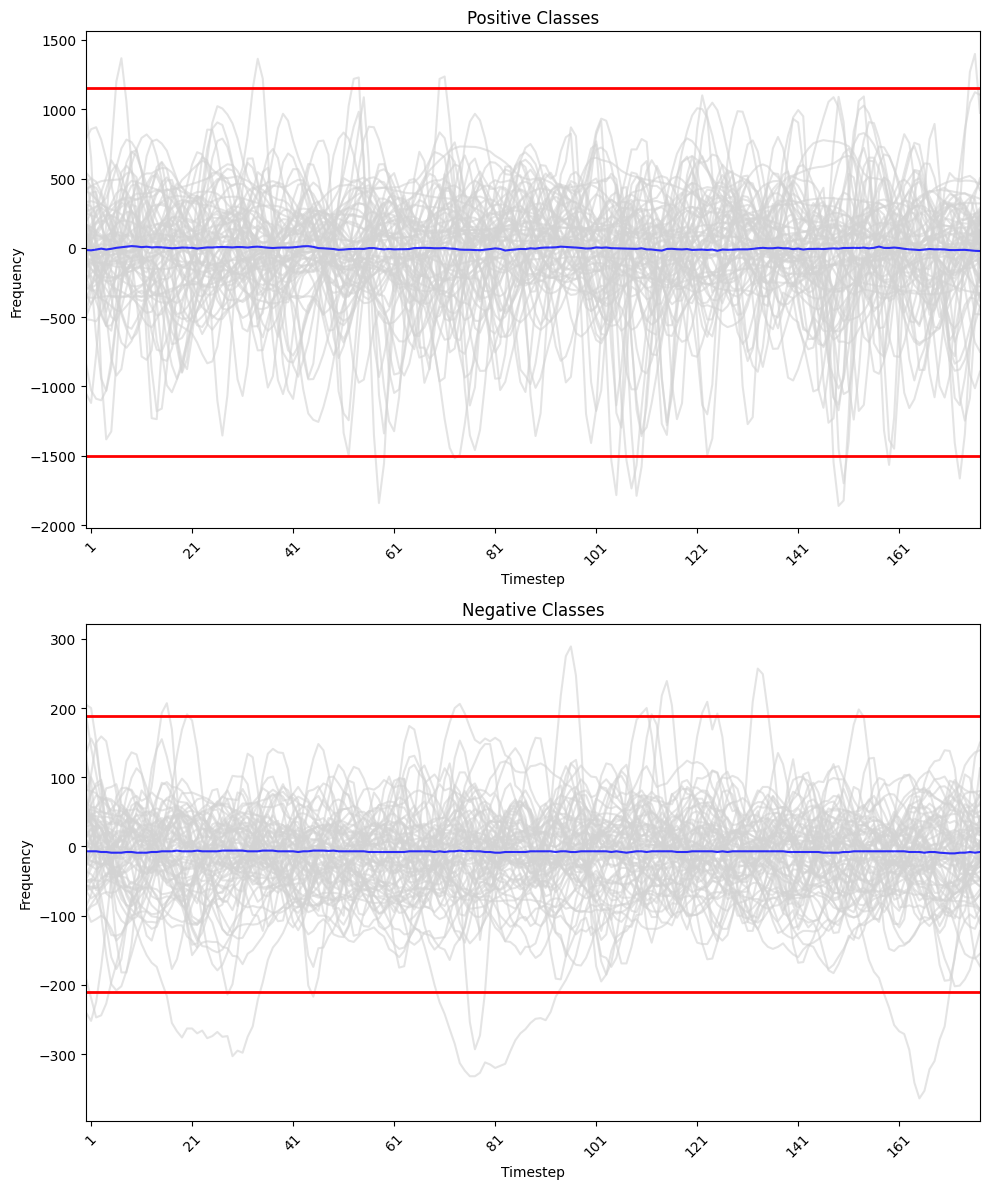

In [5]:
pos_df = raw_df.loc[raw_df['binary_y'] == 1, ~raw_df.columns.isin(['patient_id', 'binary_y'])].copy().reset_index(drop=True)
neg_df = raw_df.loc[raw_df['binary_y'] == 0, ~raw_df.columns.isin(['patient_id', 'binary_y'])].copy().reset_index(drop=True)

pos_indices = np.random.choice(np.arange(0, len(pos_df)), size=70, replace=False)
neg_indices = np.random.choice(np.arange(0, len(neg_df)), size=70, replace=False)

df_dict = {
    0:(pos_df, pos_indices),
    1:(neg_df, neg_indices)
}

viz_sampled_eeg(df_dict)

# very apparent that 1-second examples of positive classes tend to have much higher/wider swings (~1200 to -1500) as compared to negative classes (~200 to -200).
# merit w.r.t. using statistical measures as feature descriptors of each 1-second example instead of time-series features -> pass as input into a trained MLP for binary classification
# plots of mean and median is very well-centered around 0 (likely not informative)
# consider: min, max, range, std, median absolute deviation, p25, p75, IQR, line-length (sum of absolute differences between timesteps, intuitively line plot per examples can be viewed as a string where positive examples are expected to have a much longer line length when 'stretched' vs negative examples

In [6]:
ts_X_train, ts_y_train, ts_X_val, ts_y_val, ts_X_test, ts_y_test = generate_splits(raw_df, 'time-series', SEED)
weights_tensor = generate_class_weights(ts_y_train, DEVICE) # deterministic once training set split is established

assert len(ts_X_train) + len(ts_X_val) + len(ts_X_test) == len(raw_df)

In [7]:
EPOCHS = 35
RERUN_TS_HPO = False

ts_train_dataset = TimeSeriesDataset(ts_X_train, ts_y_train)
ts_val_dataset = TimeSeriesDataset(ts_X_val, ts_y_val)
ts_test_dataset = TimeSeriesDataset(ts_X_test, ts_y_test)

if RERUN_TS_HPO:
    ts_best_params, ts_best_mcc = run_hpo(lambda trial:ts_objective(trial, ts_train_dataset, ts_val_dataset, weights_tensor, DEVICE, EPOCHS), n_trials=20)
    save_best_params(MODELS_DIR / 'best_params_ts.json', ts_best_mcc, ts_best_params)
else:
    ts_best_params, ts_best_mcc = load_best_params(MODELS_DIR / 'best_params_ts.json')
print(f'Best trial for Time-series HPO has MCC value: {ts_best_mcc} and parameters: {ts_best_params}')

Best trial for Time-series HPO has MCC value: 0.9157428741455078 and parameters: {'num_layers': 6, 'dropout': 0.31011190827700863, 'out_channels': 14, 'k': 7, 'stride': 1, 'lr': 0.0008208675318908454}


Last Epoch Train Loss: 0.042, Last Epoch Val Loss: 0.094


c:\Users\Admin\Desktop\Course_Materials\eeg_seizure_recognition\.venv\Lib\site-packages\torch\nn\modules\transformer.py:392: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.norm_first was True
  warnings.warn(


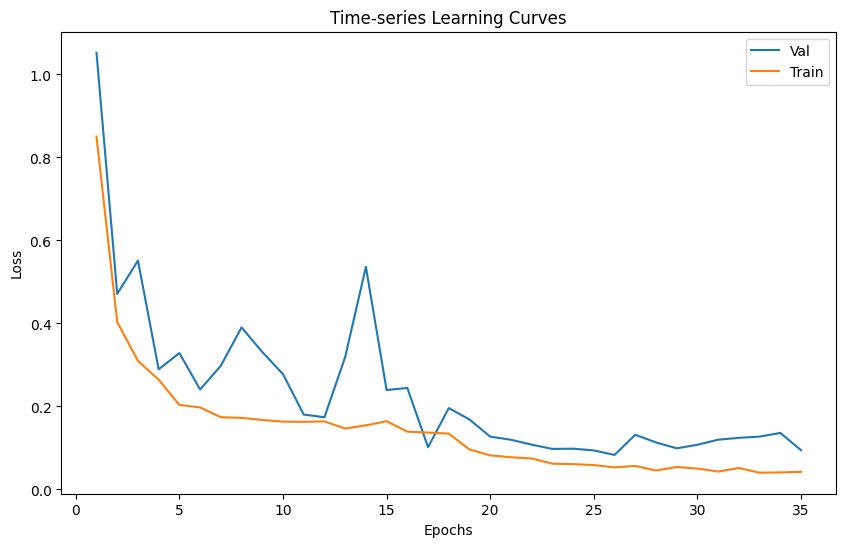

Time-series Validation Performance


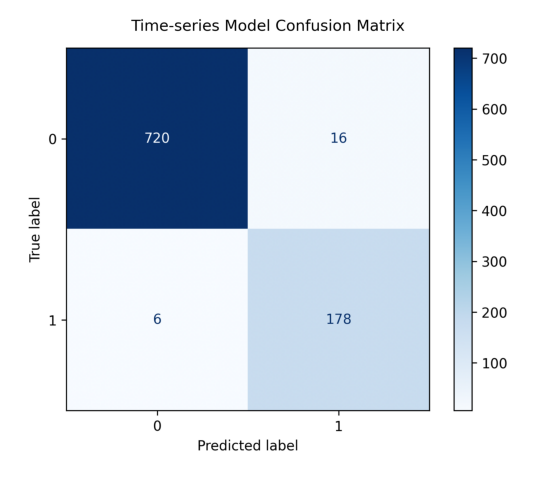

              precision    recall  f1-score   support

           0       0.99      0.98      0.98       736
           1       0.92      0.97      0.94       184

    accuracy                           0.98       920
   macro avg       0.95      0.97      0.96       920
weighted avg       0.98      0.98      0.98       920

Best Time-series Val MCC Score: 0.927
Best Time-series Val Loss (Epoch: 29): 0.099
Best Time-series Train Loss (Epoch: 29): 0.054


In [8]:
RERUN_TS_TRAIN_VAL = False

if RERUN_TS_TRAIN_VAL:
    ts_out_dict = ts_train_val_loop(ts_train_dataset, ts_val_dataset, weights_tensor, DEVICE, epochs=EPOCHS, **ts_best_params)
    ts_model = ts_out_dict['model']
    save_out_dict(ts_out_dict, MODELS_DIR / 'out_dict_ts.json')
else:
    ts_out_dict = load_out_dict(MODELS_DIR / 'out_dict_ts.json')
    ts_model = load_trained_model('time-series', ts_train_dataset, ts_best_params, ts_out_dict['state_dict_path'], DEVICE)

generate_val_report(ts_out_dict, 'time-series', from_saved=not RERUN_TS_TRAIN_VAL)

In [9]:
# feature engineering
stat_features = extract_stat_features(raw_df)
clean_df = build_clean_df(raw_df, stat_features) # no transformations applied outside of element-wise log-transformation on length feature

assert len(clean_df) == 11500
assert len(clean_df.columns) == 11
assert clean_df.isna().any().any() == False

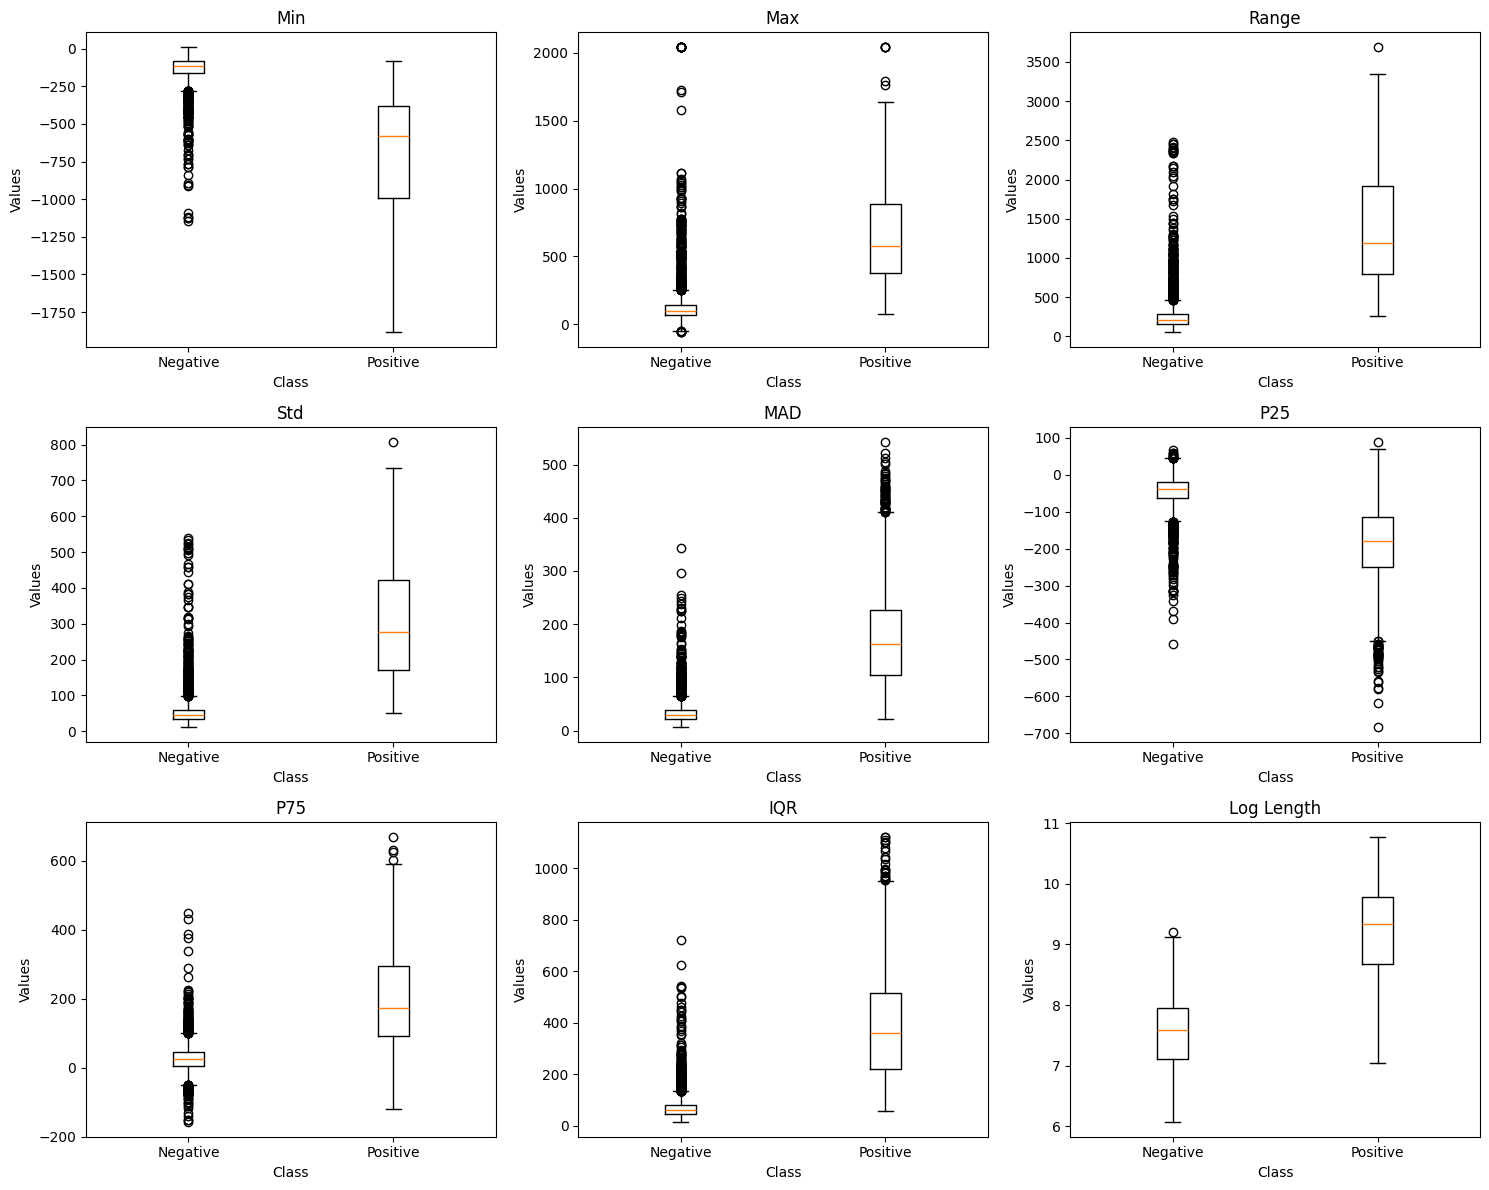

In [10]:
# boxplot comparison of class-stratified dist to evaluate discriminability of features engineered
viz_feature_boxplots(clean_df)

,patient_id,min_vals_pt,max_vals_pt,range_vals_pt,std_vals_pt,mad_vals_pt,p25_vals_pt,p75_vals_pt,iqr_vals_pt,log_length,binary_y
0,V1.791,-0.496208,0.229652,0.805421,0.686941,0.754038,-0.199597,0.061691,0.698203,8.648221,0
1,V1.924,-3.110436,1.183522,1.871439,1.842140,1.490410,-0.340490,2.392197,1.652412,9.549595,1
2,V1.1,0.291149,-0.468635,-0.337029,-0.325475,-0.188685,-0.190650,-0.971965,-0.223032,7.807103,0
3,V1.60,0.445858,-2.772622,-2.096450,-2.414488,-2.385693,-0.217438,-2.649568,-2.543113,6.977282,0
4,V1.54,0.461699,-0.480386,-0.543963,-0.542699,-0.435479,0.400376,-0.233924,-0.438529,7.914983,0
5,V1.56,0.561615,-0.242377,-0.285610,-0.167722,-0.140809,0.611463,0.020048,-0.198959,7.705263,0
6,V1.191,0.217313,-0.149824,0.096358,0.227436,0.438125,0.357852,0.223143,0.422792,8.230310,0
7,V1.273,0.347766,-0.738697,-0.786568,-0.614301,-2.060224,0.071116,-0.876446,-0.794482,6.754604,0
8,V1.874,-0.905303,0.896977,1.232528,1.124814,1.227508,-1.051478,0.330251,1.250733,8.579228,1
9,V1.491,0.588034,-0.516325,-0.753339,-0.957702,-1.175390,0.711364,-0.207653,-1.142478,7.644441,0


,min_vals_pt,max_vals_pt,range_vals_pt,std_vals_pt,mad_vals_pt,p25_vals_pt,p75_vals_pt,iqr_vals_pt,log_length
count,11500.0,11500.0,11500.0,11500.0,11500.0,11500.0,11500.0,11500.0,11500.0
mean,0.0,0.0,-0.000001,-0.0,0.0,0.0,0.0,-0.000001,7.89139
std,1.000043,1.000043,1.000044,1.000044,1.000044,1.000043,1.000043,1.000044,0.896487
min,-3.286913,-7.467308,-3.512785,-3.534077,-3.939085,-5.591411,-7.084171,-4.030509,6.066108
25%,-0.25015,-0.510261,-0.629081,-0.645516,-0.636446,-0.343383,-0.379598,-0.642363,7.227663
50%,0.237021,-0.2676,-0.090596,-0.109115,-0.095062,0.19444,-0.122674,-0.097213,7.765145
75%,0.570352,0.132548,0.60633,0.62084,0.617132,0.518021,0.225609,0.616872,8.29611
max,15.666687,4.507771,2.094667,2.058348,2.159182,6.619896,4.811729,2.115577,10.775618
dtypes,float32,float32,float32,float32,float32,float32,float32,float32,float32
sparsity,0,0,0,0,0,0,0,0,0


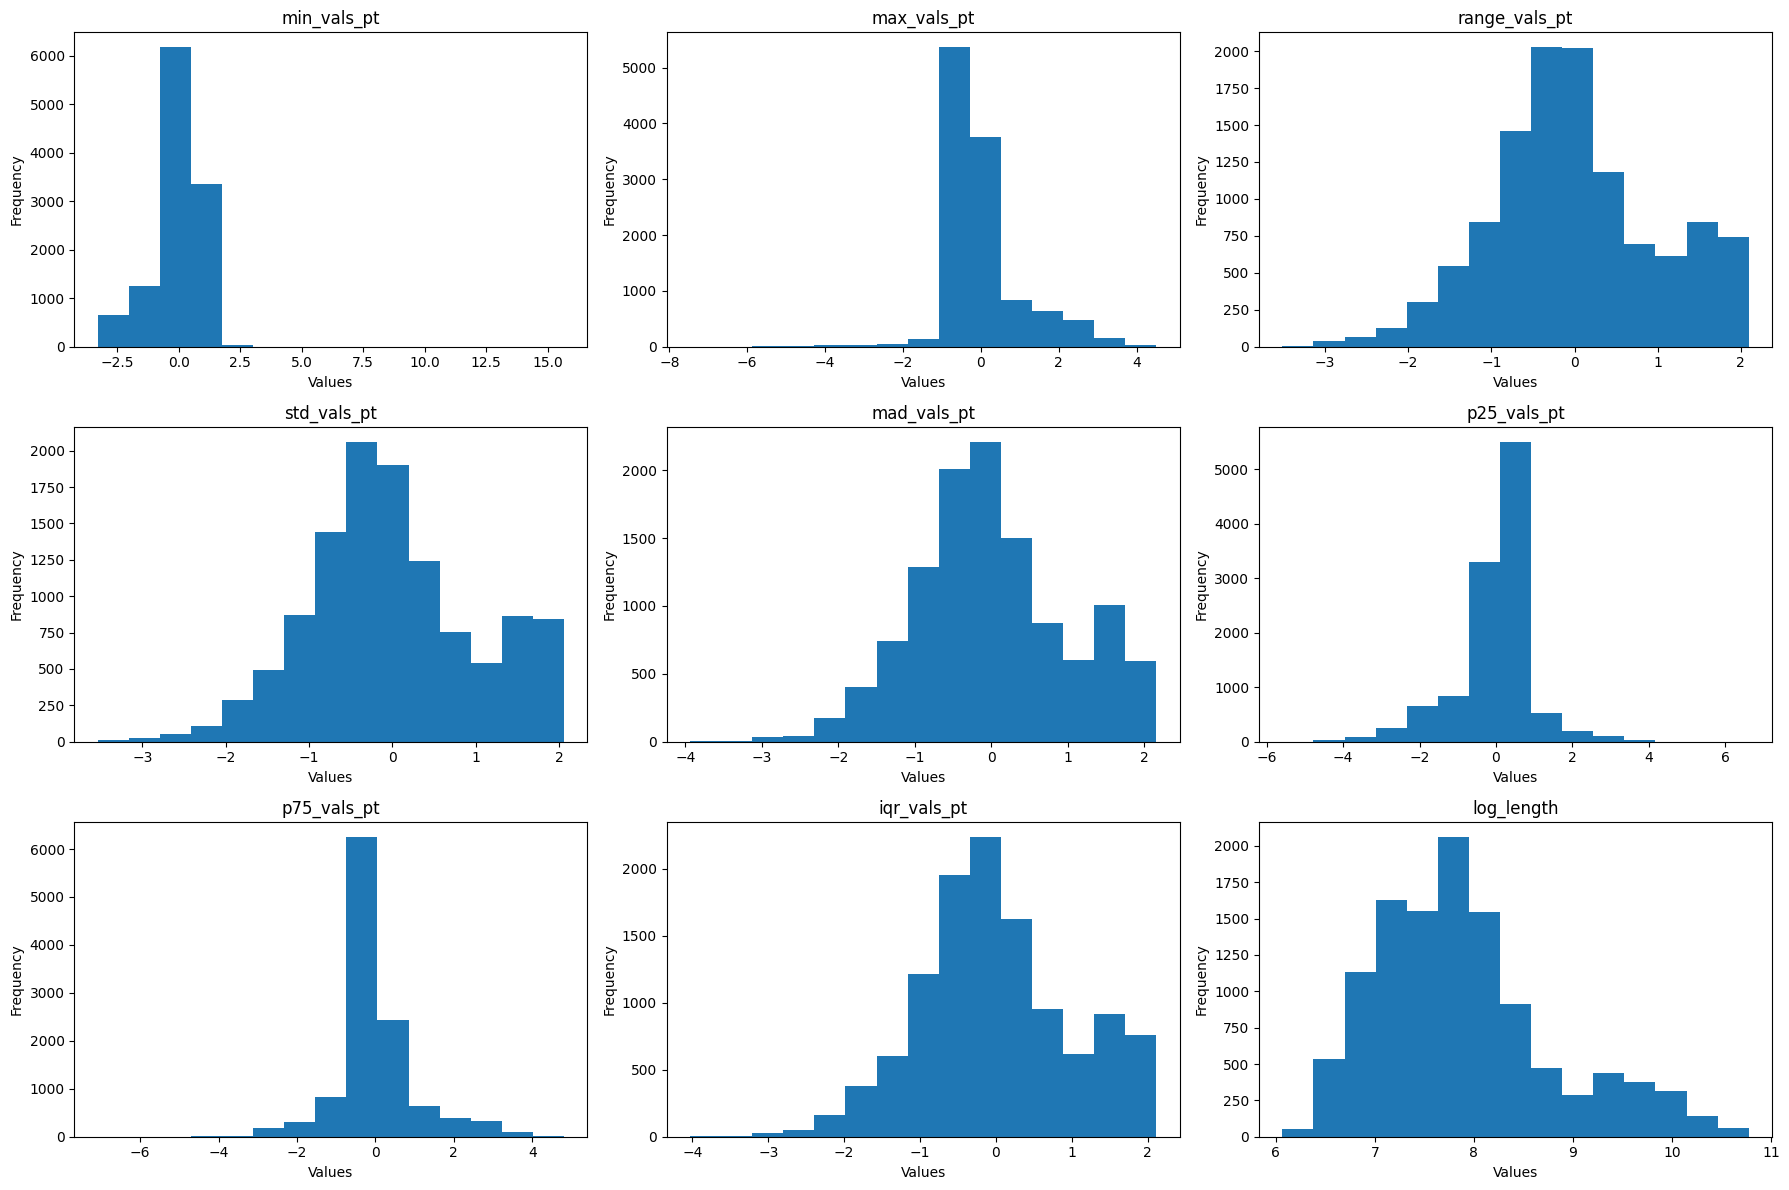

In [11]:
# EDA on statistical features/descriptors WITH Yeo-Johnson transformation
new_df = build_yj_df(raw_df, stat_features)

assert len(new_df) == 11500
assert len(new_df.columns) == 11
assert new_df.isna().any().any() == False

display(new_df.head(10))

features_df, summ_stats = summarize_features(new_df)
display(summ_stats)

viz_feature_hists(features_df)
# yeo-johnson range cross-comparability improves w z-norm, also not good having non-0 mean vs all other z-normed y-j features

In [12]:
assert (raw_df['patient_id'] == clean_df['patient_id']).all()
assert raw_df.index.equals(clean_df.index)
assert len(raw_df) == len(clean_df)
assert (raw_df['patient_id'].values == clean_df['patient_id'].values).all()  # positional, not index-aligned

mlp_X_train, mlp_y_train, mlp_X_val, mlp_y_val, mlp_X_test, mlp_y_test = generate_splits(clean_df, 'mlp', SEED)

assert np.array_equal(mlp_y_train, ts_y_train)
assert np.array_equal(mlp_y_val, ts_y_val)
assert np.array_equal(mlp_y_test, ts_y_test)

In [13]:
RERUN_MLP_HPO = False

mlp_train_dataset = ScaledMLPDataset(mlp_X_train, mlp_y_train)
mlp_val_dataset = ScaledMLPDataset(mlp_X_val, mlp_y_val)
mlp_test_dataset = ScaledMLPDataset(mlp_X_test, mlp_y_test)

if RERUN_MLP_HPO:
    mlp_best_params, mlp_best_mcc = run_hpo(lambda trial:mlp_objective(trial, mlp_train_dataset, mlp_val_dataset, weights_tensor, DEVICE, EPOCHS, batch_size=64, num_classes=2, weight_decay=1e-3), n_trials=20)
    save_best_params(MODELS_DIR / 'best_params_mlp.json', mlp_best_mcc, mlp_best_params)
else:
    mlp_best_params, mlp_best_mcc = load_best_params(MODELS_DIR / 'best_params_mlp.json')
print(f'Best trial for MLP HPO has MCC value: {mlp_best_mcc} and parameters: {mlp_best_params}')

Best trial for MLP HPO has MCC value: 0.9692922830581665 and parameters: {'num_layers': 9, 'num_nodes': 123, 'dropout': 0.23285388808916202, 'lr': 4.67012466170634e-05}


Last Epoch Train Loss: 0.199, Last Epoch Val Loss: 0.084


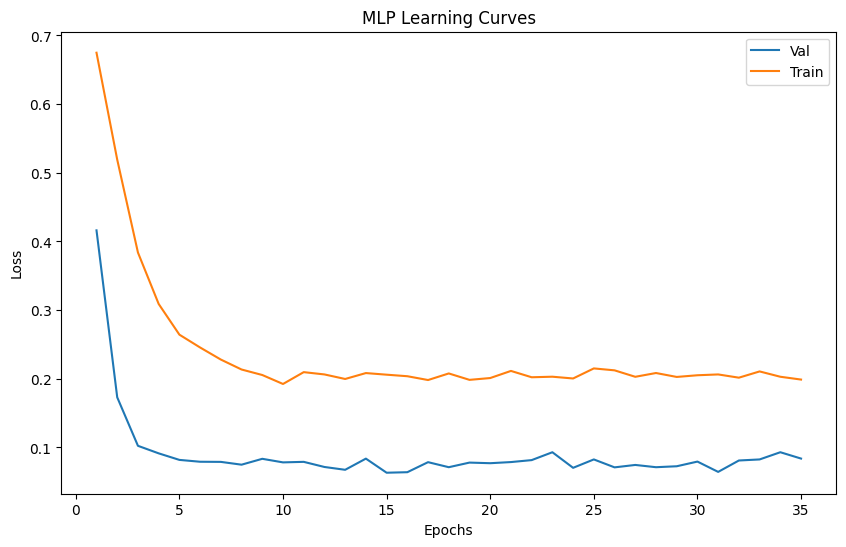

MLP Validation Performance


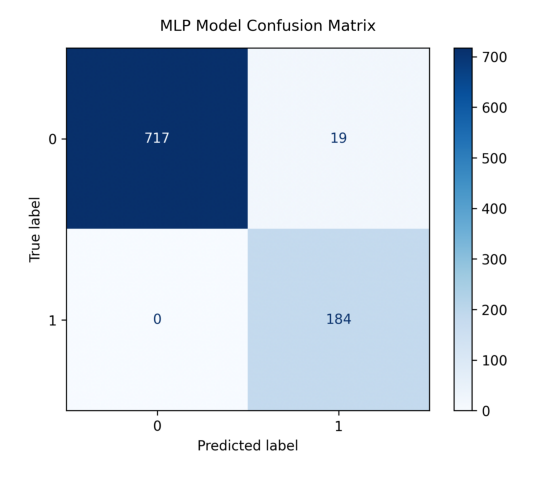

              precision    recall  f1-score   support

           0       1.00      0.97      0.99       736
           1       0.91      1.00      0.95       184

    accuracy                           0.98       920
   macro avg       0.95      0.99      0.97       920
weighted avg       0.98      0.98      0.98       920

Best MLP Val MCC Score: 0.940
Best MLP Val Loss (Epoch: 23): 0.093
Best MLP Train Loss (Epoch: 23): 0.203


In [14]:
RERUN_MLP_TRAIN_VAL = False

if RERUN_MLP_TRAIN_VAL:
    mlp_out_dict = mlp_train_val_loop(mlp_train_dataset, mlp_val_dataset, weights_tensor, DEVICE, EPOCHS, **mlp_best_params)
    mlp_model = mlp_out_dict['model']
    save_out_dict(mlp_out_dict, MODELS_DIR / 'out_dict_mlp.json')
else:
    mlp_out_dict = load_out_dict(MODELS_DIR / 'out_dict_mlp.json')
    mlp_model = load_trained_model('mlp', mlp_train_dataset, mlp_best_params, mlp_out_dict['state_dict_path'], DEVICE)

mlp_best_mcc = mlp_out_dict['best_eval_metric']
mlp_state_dict_path = mlp_out_dict['state_dict_path']
generate_val_report(mlp_out_dict, 'mlp', from_saved=not RERUN_MLP_TRAIN_VAL)

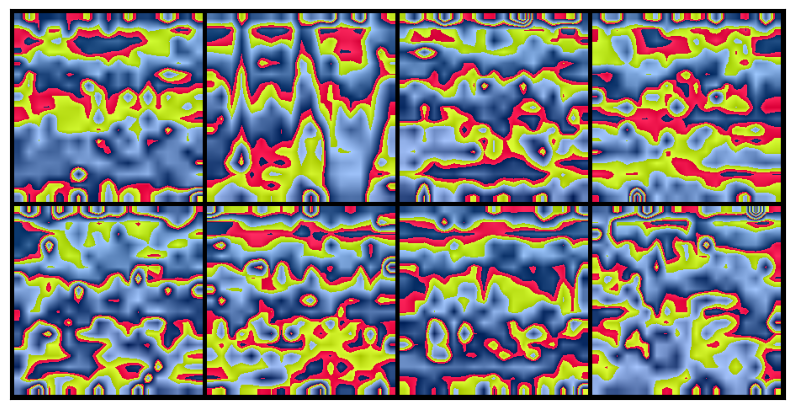

In [15]:
# visualize transformation pipeline output
viz_spectrograms(raw_df, transform)

In [16]:
assert (raw_df['patient_id'] == clean_df['patient_id']).all()
assert raw_df.index.equals(clean_df.index)
assert len(raw_df) == len(clean_df)
assert (raw_df['patient_id'].values == clean_df['patient_id'].values).all()  # positional, not index-aligned

resnet_X_train, resnet_y_train, resnet_X_val, resnet_y_val, resnet_X_test, resnet_y_test = generate_splits(raw_df, 'resnet', SEED)

assert np.array_equal(mlp_y_train, resnet_y_train)
assert np.array_equal(mlp_y_val, resnet_y_val)
assert np.array_equal(mlp_y_test, resnet_y_test)

Last Epoch Train Loss [STAGE 1]: 0.173, Last Epoch Val Loss [STAGE 1]: 0.180
Last Epoch Train Loss [STAGE 2]: 0.001, Last Epoch Val Loss [STAGE 2]: 0.086


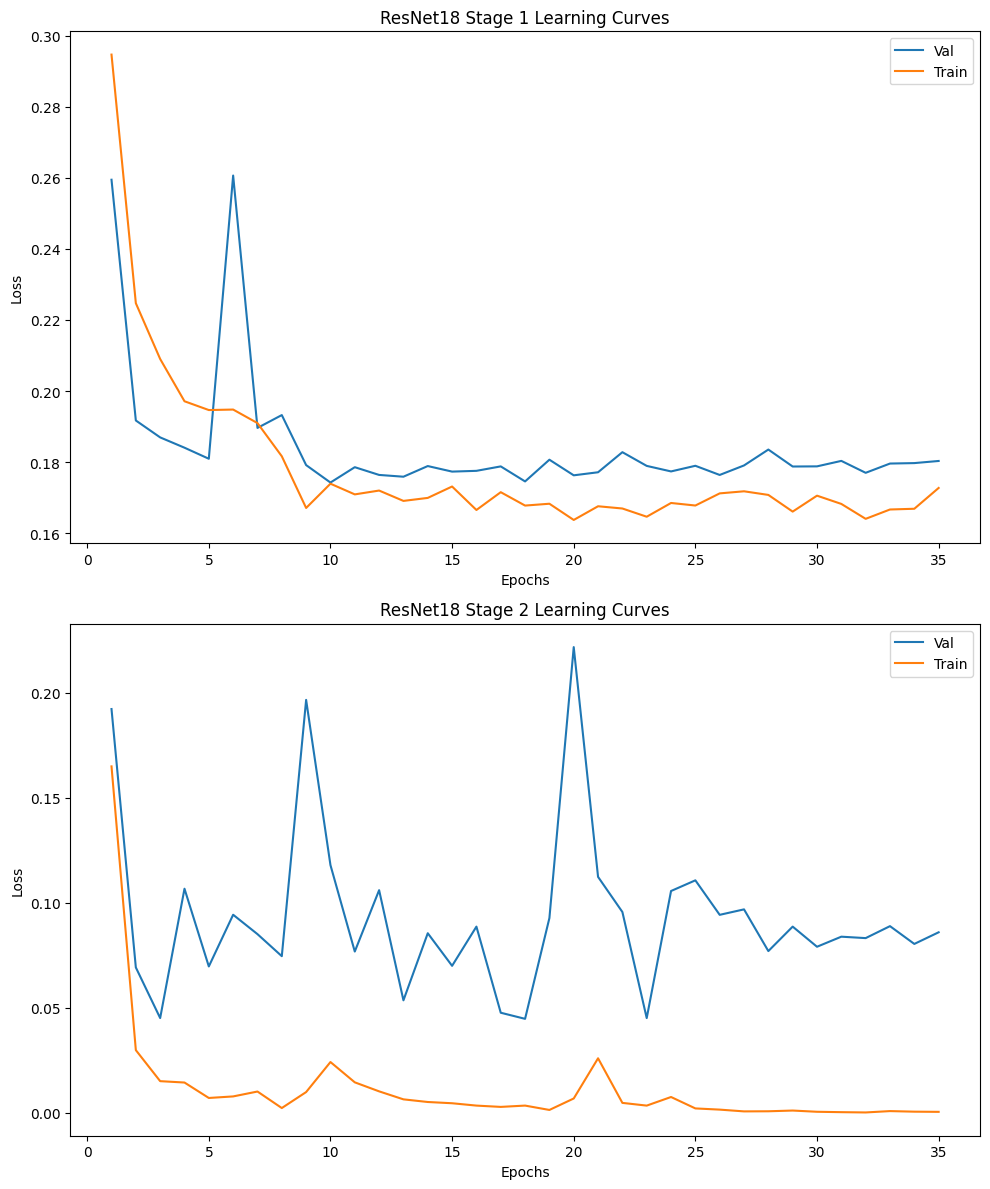

ResNet18 Validation Performance


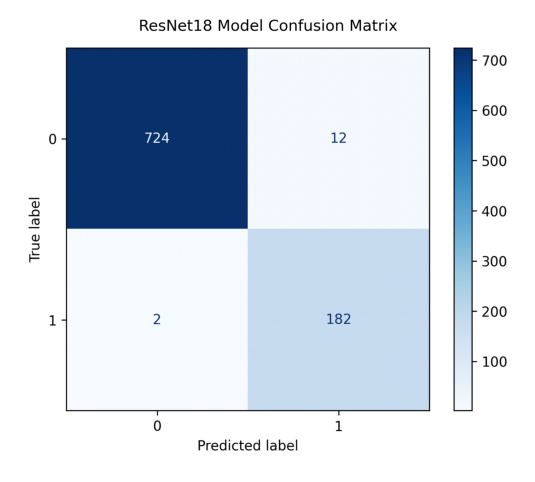

              precision    recall  f1-score   support

           0       1.00      0.98      0.99       736
           1       0.94      0.99      0.96       184

    accuracy                           0.98       920
   macro avg       0.97      0.99      0.98       920
weighted avg       0.99      0.98      0.98       920

Best ResNet18 Val MCC Score: 0.954
Best ResNet18 Val Loss ([STAGE 2] Epoch: 23): 0.045
Best ResNet18 Train Loss ([STAGE 2] Epoch: 23): 0.004


In [17]:
RERUN_RESNET_TRAIN_VAL = False

resnet_train_dataset = SpectrogramImageDataset(resnet_X_train, resnet_y_train, transform)
resnet_val_dataset = SpectrogramImageDataset(resnet_X_val, resnet_y_val, transform)
resnet_test_dataset = SpectrogramImageDataset(resnet_X_test, resnet_y_test, transform)

if RERUN_RESNET_TRAIN_VAL:
    resnet_out_dict = resnet_train_val_loop(resnet_train_dataset, resnet_val_dataset, weights_tensor, DEVICE, EPOCHS)
    resnet_model = resnet_out_dict['model']
    save_out_dict(resnet_out_dict, MODELS_DIR / 'out_dict_resnet.json')
else:
    resnet_out_dict = load_out_dict(MODELS_DIR / 'out_dict_resnet.json')
    resnet_model = load_trained_model('resnet', resnet_train_dataset, None, resnet_out_dict['best_state_dict_path'], DEVICE)

resnet_best_mcc = resnet_out_dict['best_eval_metric']
resnet_state_dict_path = resnet_out_dict['best_state_dict_path']
generate_val_report(resnet_out_dict, 'resnet', from_saved=not RERUN_RESNET_TRAIN_VAL)

In [18]:
RERUN_MULT_HPO = False

assert (raw_df['patient_id'] == clean_df['patient_id']).all()
assert raw_df.index.equals(clean_df.index)
assert len(raw_df) == len(clean_df)
assert (raw_df['patient_id'].values == clean_df['patient_id'].values).all()  # positional, not index-aligned

assert np.array_equal(mlp_y_train, resnet_y_train)
assert np.array_equal(mlp_y_val, resnet_y_val)
assert np.array_equal(mlp_y_test, resnet_y_test)

mult_train_dataset = MultiModalDataset(mlp_X_train, resnet_X_train, mlp_y_train, transform)
mult_val_dataset = MultiModalDataset(mlp_X_val, resnet_X_val, mlp_y_val, transform)
mult_test_dataset = MultiModalDataset(mlp_X_test, resnet_X_test, mlp_y_test, transform)

if RERUN_MULT_HPO:
    mult_best_params, mult_best_mcc = run_hpo(lambda trial:mult_objective(trial, mult_train_dataset, mult_val_dataset, weights_tensor, DEVICE, EPOCHS, resnet_state_dict_path, mlp_state_dict_path, mlp_best_params, batch_size=64, num_classes=2, weight_decay=1e-3), n_trials=20)
    save_best_params(MODELS_DIR / 'best_params_mult.json', mult_best_mcc, mult_best_params)
else:
    mult_best_params, mult_best_mcc = load_best_params(MODELS_DIR / 'best_params_mult.json')
print(f'Best trial for Multi-Modal Model has MCC value: {mult_best_mcc} and parameters: {mult_best_params}')

Best trial for Multi-Modal Model has MCC value: 0.9831699132919312 and parameters: {'num_layers': 3, 'num_nodes': 111, 'dropout': 0.41634280467202134, 'lr': 0.0006417529069074638}


Last Epoch Train Loss: 0.002, Last Epoch Val Loss: 0.055


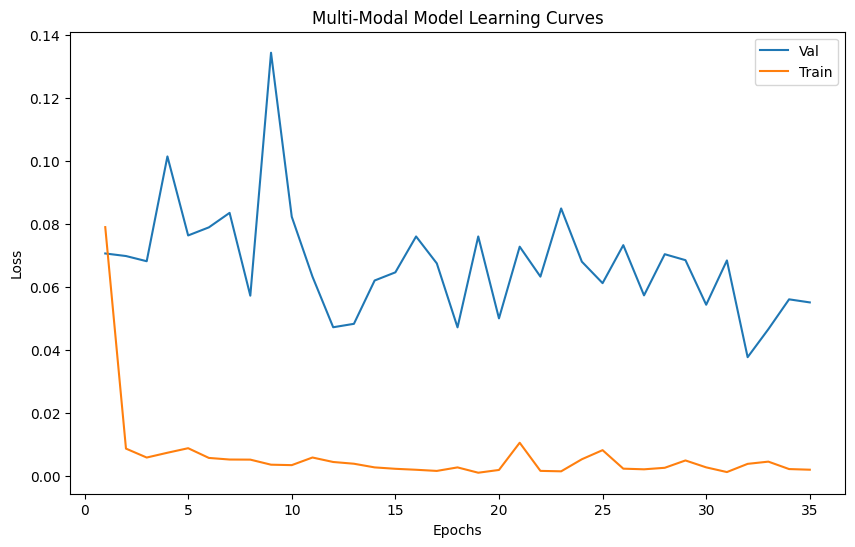

Multi-Modal Model Validation Performance


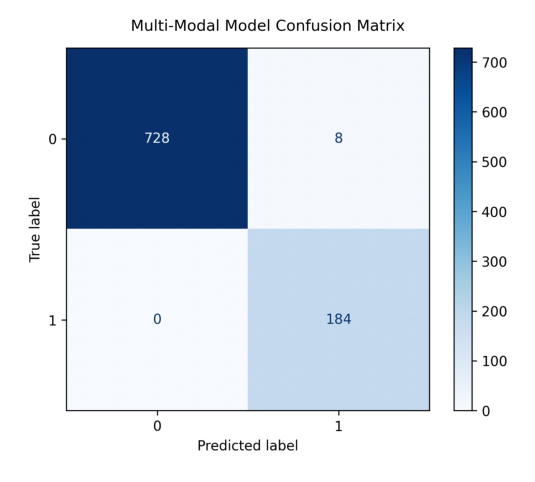

              precision    recall  f1-score   support

           0       1.00      0.99      0.99       736
           1       0.96      1.00      0.98       184

    accuracy                           0.99       920
   macro avg       0.98      0.99      0.99       920
weighted avg       0.99      0.99      0.99       920

Best Multi-Modal Model Val MCC Score: 0.974
Best Multi-Modal Model Val Loss (Epoch: 32): 0.038
Best Multi-Modal Model Train Loss (Epoch: 32): 0.004


In [19]:
RERUN_MULT_TRAIN_VAL = False

if RERUN_MULT_TRAIN_VAL:
    mult_out_dict = mult_train_val_loop(mult_train_dataset, mult_val_dataset, weights_tensor, DEVICE, EPOCHS, resnet_state_dict_path, mlp_state_dict_path, mlp_best_params, **mult_best_params)
    mult_model = mult_out_dict['model']
    save_out_dict(mult_out_dict, MODELS_DIR / 'out_dict_mult.json')
else:
    mult_out_dict = load_out_dict(MODELS_DIR / 'out_dict_mult.json')
    mult_model = load_trained_model('mult', mult_train_dataset, mult_best_params, mult_out_dict['state_dict_path'], DEVICE, resnet_state_dict_path=resnet_state_dict_path, mlp_state_dict_path=mlp_state_dict_path, mlp_best_params=mlp_best_params)

mult_best_mcc = mult_out_dict['best_eval_metric']
generate_val_report(mult_out_dict, 'mult', from_saved=not RERUN_MULT_TRAIN_VAL)

[TEST]:   0%|          | 0/72 [00:00<?, ?it/s]

Multi-Modal Model Test Set Evaluation Performance


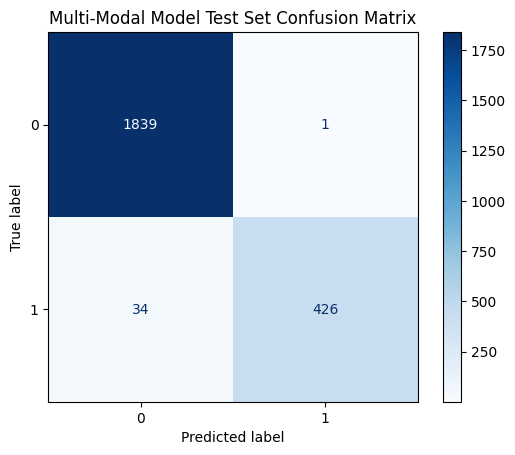

              precision    recall  f1-score   support

           0       0.98      1.00      0.99      1840
           1       1.00      0.93      0.96       460

    accuracy                           0.98      2300
   macro avg       0.99      0.96      0.98      2300
weighted avg       0.99      0.98      0.98      2300

Final MCC Score: 0.952


In [20]:
model_list = [
    ('MLP', mlp_model, mlp_best_mcc, mlp_test_dataset),
    ('ResNet18', resnet_model, resnet_best_mcc, resnet_test_dataset),
    ('Multi-Modal Model', mult_model, mult_best_mcc, mult_test_dataset),
]

eval_model(model_list, DEVICE) # test set evaluation of model with best validation MCC